# 08 · Step 8: Money simulator and budget optimiser in rupees (gate K5)
**The question:** "I have a budget. Whom do I contact, through which channel, with which offer, and how many rupees come back?"

**The one equation:** profit per customer = extra buyers × margin − reward × everyone who uses it − contact cost

| Part | Data | Question in rupees |
|---|---|---|
| A | X5 (real, SMS test), locked 20% exam | Whom to contact, which channel, and how far a budget goes |
| B | Starbucks (offers test) | Which offer pays once its real cost is counted, and who should get it |
| C | Both | Does the plan still make money if our assumptions are wrong? |

**Honesty rule:** every profit number is **measured on real outcomes of customers the models never saw** (treated vs control within each group), not taken from model predictions, and comes with a 95% range.

## Cell 0 · Setup and rupee assumptions
Every number below is an adjustable assumption with its source. Change one, then Run All to see a new answer.

In [1]:
import pandas as pd, numpy as np, duckdb, time, warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt, lightgbm as lgb
from pathlib import Path
from nudge_engine import (NudgeEngine, split_by_group, average_effects, evaluate_policies, policy_value,
                          offer_profit, breakeven_uplift, profit_curve, budget_plan)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20); pd.set_option('display.max_colwidth', 80)
X5 = Path('..') / 'data_x5' / 'features'; RAW = Path('..') / 'data_offers' / 'raw'
CHECKS = {}

# --- grocery (X5 part) ---
BASKET = 1000          # ₹ average grocery basket (assumption)
GROSS_MARGIN = 0.15    # ~15% gross margin, Indian supermarket (DMart FY21-23, derived from annual reports)
MARGIN = BASKET * GROSS_MARGIN   # ₹150 profit per extra purchase
CHANNELS = {           # ₹ per contact
    'Email': 0.01,          # bulk email via AWS SES, about $0.10 per 1,000
    'SMS': 0.10,            # promotional SMS, ₹0.08-0.12 (Message Central, 2026)
    'WhatsApp': 1.02,       # Meta marketing template ₹0.8631 + 18% GST (MyOperator, 2026)
    'AI voice call': 3.33,  # ~₹5 per minute, 40-second call (Edesy, 2026)
}
PER = 100_000          # report everything per 1 lakh customers

# --- cafe (Starbucks part) ---
PRICE = 70             # ₹ per $ of Starbucks spend: price-level conversion (US tall latte ~$5, India ~₹350), not the exchange rate
CAFE_MARGIN = 0.75     # cafe gross margin ~75% (Costa Coffee India FY25: 75.4%)
SB_CONTACT = 0.10      # ₹ per offer sent (SMS / app push)
REDEEM_CASHBACK = 0.75 # share of cashback actually used; reward breakage is typically 20-30% (Stashfin)
print(f'Profit per extra grocery purchase: ₹{MARGIN:.0f}')
display(pd.Series(CHANNELS, name='₹ per contact').to_frame())

Profit per extra grocery purchase: ₹150


,₹ per contact
Email,0.01
SMS,0.10
WhatsApp,1.02
AI voice call,3.33


## Part A · X5: whom to contact, which channel, how far a budget goes
**A1. Profit curve.** Sort customers by a score, contact the top 5%, 10% … 100%, and measure the real extra buyers in that group on the locked exam.
- **Uplift champion** (Step 4): ranks by *change caused* by the message.
- **Likely-buyer model** (Step 5, the usual industry approach): ranks by *chance of buying*.
- **Random**: no targeting.

The curve rises while we add persuadable customers, flattens, and falls if we add customers the message hurts. **The peak = the best number of people to contact.**

locked exam: 40,008 customers, scaled to 100,000 | prepared in 6s


,Uplift champion: profit ₹,Likely-buyer model: profit ₹,Random: profit ₹,Uplift: extra buyers
share contacted,,,,
0.0,0.0,0.0,0.0,0.0
0.1,174300.0,3000.0,40700.0,1169.0
0.2,264000.0,20500.0,113100.0,1774.0
0.3,270100.0,55600.0,176200.0,1820.0
0.4,281900.0,122100.0,189900.0,1906.0
0.5,321800.0,167100.0,243000.0,2179.0
0.6,389700.0,259600.0,275500.0,2638.0
0.7,463400.0,337700.0,341900.0,3136.0
0.8,452500.0,420900.0,342700.0,3070.0


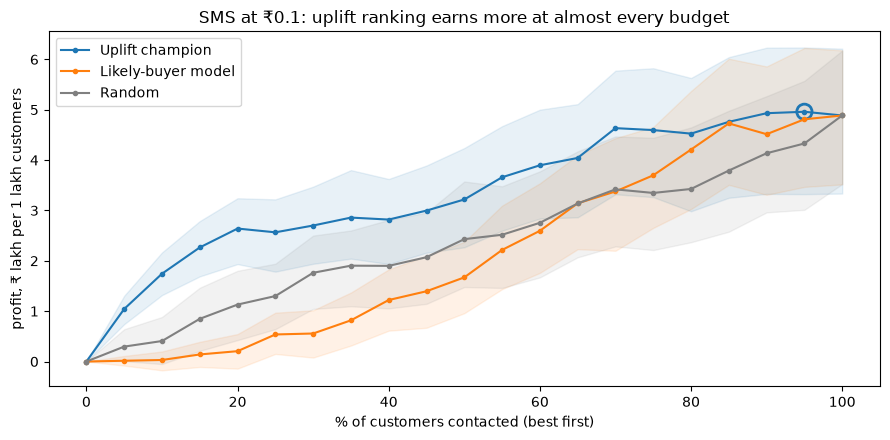

Peak: contact 95% -> 3,370 extra buyers, profit ₹495,972 (95% range ₹332,402 to ₹623,614)


In [2]:
t0 = time.time()
prof = duckdb.sql(f"SELECT * FROM '{(X5 / 'customer_profiles.parquet').as_posix()}' WHERE in_experiment = 1").df()
prof = pd.concat([prof, pd.get_dummies(prof.gender, prefix='gender').astype(int)], axis=1)
XC = [c for c in prof.columns if c not in {'client_id', 'gender', 'treatment_flg', 'target', 'in_experiment'}]
prof[XC] = prof[XC].astype('float32')
hs = duckdb.sql(f"SELECT client_id, champion FROM '{(X5 / 'holdout_scores.parquet').as_posix()}'").df()
hold = prof.merge(hs, on='client_id'); dev = prof[~prof.client_id.isin(hs.client_id)]
dt = dev[dev.treatment_flg == 1]          # likely-buyer model, exactly as in Step 5
likely = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=400, subsample=0.8, subsample_freq=1,
                            colsample_bytree=0.7, reg_lambda=5.0, verbose=-1, random_state=42).fit(dt[XC], dt.target)
SCORES = {'Uplift champion': hold.champion.values, 'Likely-buyer model': likely.predict_proba(hold[XC])[:, 1],
          'Random': np.random.default_rng(0).random(len(hold))}
T, Y, SCALE = hold.treatment_flg.values, hold.target.values.astype(float), PER / len(hold)
print(f'locked exam: {len(hold):,} customers, scaled to {PER:,} | prepared in {time.time() - t0:.0f}s')

cost = CHANNELS['SMS']
CURVES = {k: profit_curve(s, T, Y, MARGIN, cost, scale=SCALE, n_boot=200) for k, s in SCORES.items()}
tab = pd.DataFrame({'share contacted': CURVES['Uplift champion'].share})
for k, c in CURVES.items(): tab[f'{k}: profit ₹'] = c.profit.round(-2)
tab['Uplift: extra buyers'] = CURVES['Uplift champion'].extra_units.round(0)
display(tab.iloc[::2].set_index('share contacted'))
fig, ax = plt.subplots(figsize=(9, 4.5))
for (k, c), col in zip(CURVES.items(), ['tab:blue', 'tab:orange', 'grey']):
    ax.plot(c.share * 100, c.profit / 1e5, marker='o', ms=3, color=col, label=k); ax.fill_between(c.share * 100, c.low95 / 1e5, c.high95 / 1e5, color=col, alpha=0.1)
pk = CURVES['Uplift champion'].loc[CURVES['Uplift champion'].profit.idxmax()]
ax.scatter([pk.share * 100], [pk.profit / 1e5], s=120, facecolors='none', edgecolors='tab:blue', lw=2)
ax.set_xlabel('% of customers contacted (best first)'); ax.set_ylabel('profit, ₹ lakh per 1 lakh customers')
ax.set_title(f'SMS at ₹{cost}: uplift ranking earns more at almost every budget'); ax.legend(); plt.tight_layout(); plt.show()
print(f"Peak: contact {pk.share:.0%} -> {pk.extra_units:,.0f} extra buyers, profit ₹{pk.profit:,.0f} (95% range ₹{pk.low95:,.0f} to ₹{pk.high95:,.0f})")

**A2. Channel ladder.** The cheaper the channel, the closer the best plan is to "contact everyone". As the channel gets expensive, contacting only the right people matters more.
- **Break-even uplift** = the smallest extra buy chance that pays for one contact = cost ÷ margin.

In [3]:
rows = []
for ch, c in CHANNELS.items():
    cu = profit_curve(SCORES['Uplift champion'], T, Y, MARGIN, c, scale=SCALE)
    best = cu.loc[cu.profit.idxmax()]; allc = cu.iloc[-1]
    rows.append({'channel': ch, '₹ per contact': c, 'break-even uplift (pts)': round(100 * float(breakeven_uplift(0, MARGIN, c)), 2),
                 'best share to contact': f'{best.share:.0%}', 'profit at best ₹': round(best.profit, -2),
                 'profit if contact all ₹': round(allc.profit, -2), 'saved by targeting ₹': round(best.profit - allc.profit, -2),
                 'contact spend avoided ₹': round((allc.contacts - best.contacts) * c, -2)})
LADDER = pd.DataFrame(rows).set_index('channel'); display(LADDER)

,₹ per contact,break-even uplift (pts),best share to contact,profit at best ₹,profit if contact all ₹,saved by targeting ₹,contact spend avoided ₹
channel,,,,,,,
Email,0.01,0.01,95%,504500.0,497600.0,6900.0,0.0
SMS,0.10,0.07,95%,496000.0,488600.0,7400.0,500.0
WhatsApp,1.02,0.68,90%,410300.0,396600.0,13700.0,10200.0
AI voice call,3.33,2.22,70%,237300.0,165600.0,71700.0,99900.0


**A3. Budget optimiser.** A fixed budget buys a fixed number of contacts. Which customers should get them?
Example: WhatsApp at ₹1.02. With ₹20,000 we can reach about 20% of 1 lakh customers.

,Uplift champion: contacts,Uplift champion: profit ₹,Likely-buyer model: contacts,Likely-buyer model: profit ₹,Random: contacts,Random: profit ₹
budget ₹,,,,,,
10000,9000,151600.0,1999,800.0,9000,30400.0
20000,19001,243600.0,13999,3300.0,19001,99600.0
40000,35000,253600.0,38999,86300.0,34000,166900.0
60000,58000,321400.0,58000,188100.0,57001,226400.0
110000,96000,422100.0,99000,406500.0,100000,396600.0


₹20,000 WhatsApp budget: uplift beats likely-buyer by ₹246,299 (95% range ₹177,507 to ₹319,244)


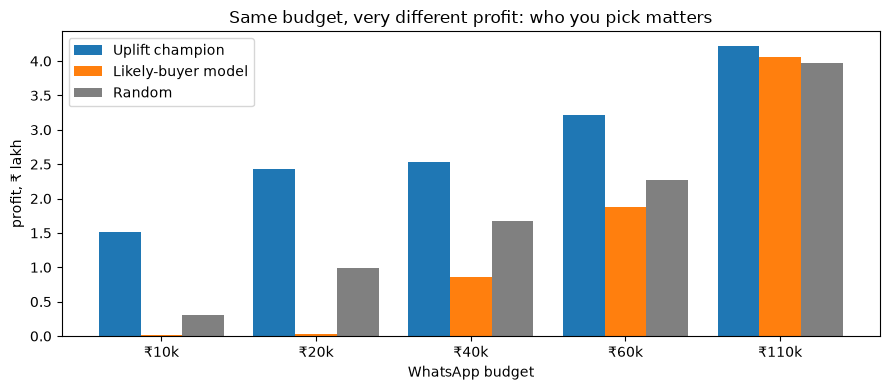

In [4]:
wa = CHANNELS['WhatsApp']
WC = {k: profit_curve(s, T, Y, MARGIN, wa, scale=SCALE, n_boot=200, shares=np.round(np.arange(0, 1.0001, 0.01), 2)) for k, s in SCORES.items()}
rows = []
for b in [10_000, 20_000, 40_000, 60_000, 110_000]:
    r = {'budget ₹': b}
    for k, c in WC.items():
        p = budget_plan(c, b, wa); r[f'{k}: contacts'] = int(p.contacts); r[f'{k}: profit ₹'] = round(p.profit, -2)
    rows.append(r)
BUD = pd.DataFrame(rows).set_index('budget ₹'); display(BUD)
# uncertainty: uplift minus likely-buyer at a ₹20,000 budget (paired bootstrap)
rng = np.random.default_rng(7); n = len(hold); k20 = int(round(20_000 / wa / SCALE)); d = []
for _ in range(300):
    i = rng.integers(0, n, n); v = []
    for s in [SCORES['Uplift champion'], SCORES['Likely-buyer model']]:
        o = i[np.argsort(-s[i], kind='stable')][:k20]
        v.append((Y[o][T[o] == 1].mean() - Y[o][T[o] == 0].mean()) * k20 * SCALE * MARGIN - k20 * SCALE * wa)
    d.append(v[0] - v[1])
lo, hi = np.percentile(d, [2.5, 97.5])
print(f'₹20,000 WhatsApp budget: uplift beats likely-buyer by ₹{np.mean(d):,.0f} (95% range ₹{lo:,.0f} to ₹{hi:,.0f})')
CHECKS['Budget-limited: uplift ranking beats likely-buyer, 95% range above zero (₹20k WhatsApp)'] = lo > 0
fig, ax = plt.subplots(figsize=(9, 4))
w = 0.27; xs = np.arange(len(BUD))
for j, (k, col) in enumerate(zip(SCORES, ['tab:blue', 'tab:orange', 'grey'])):
    ax.bar(xs + (j - 1) * w, BUD[f'{k}: profit ₹'] / 1e5, w, color=col, label=k)
ax.set_xticks(xs, [f'₹{b // 1000}k' for b in BUD.index]); ax.set_xlabel('WhatsApp budget'); ax.set_ylabel('profit, ₹ lakh')
ax.set_title('Same budget, very different profit: who you pick matters'); ax.legend(); plt.tight_layout(); plt.show()

## Part B · Starbucks: which offer pays once its real cost is counted?
Each offer type maps to the Indian offer ladder and has its own **cost rule**:

| Starbucks offer | Indian equivalent | Real cost to the company |
|---|---|---|
| Informational | Reminder (SMS / push) | contact cost only |
| Discount ("spend ₹X, get ₹Y back") | Threshold cashback / discount | the full reward, to everyone who completes it |
| BOGO (buy one, get one) | Freebie | only the **cost of goods** of the free item (25% of its price at a 75% margin) |

Value per customer-wave (₹) = spend × ₹70 per $ × 75% margin − reward paid × ₹70 × its cost share. Starbucks is simulated data, so Part B shows **the method**; a real company plugs in its own pilot.

102,000 customer-waves prepared in 3s


,extra gross profit ₹,reward cost ₹,contact ₹,net extra profit ₹
offer,,,,
informational,194.5,0.0,0.1,194.4
discount,264.4,63.2,0.1,201.1
bogo,305.6,47.0,0.1,258.5


,extra_value,low95,high95,rows
option,,,,
bogo,258.5,231.1,285.9,30499
discount,201.1,174.7,227.5,30543
informational,194.4,164.1,224.8,15235


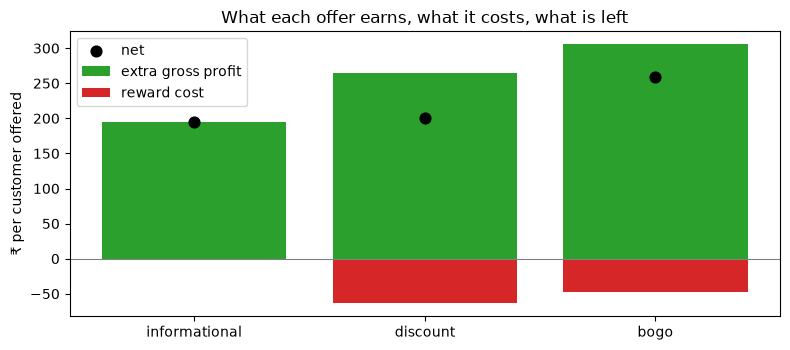

In [5]:
t0 = time.time()
pf = pd.read_json(RAW / 'starbucks_portfolio.json.gz', lines=True, compression='gzip')
pr = pd.read_json(RAW / 'starbucks_profile.json.gz', lines=True, compression='gzip')
tr_ = pd.read_json(RAW / 'starbucks_transcript.json.gz', lines=True, compression='gzip')
tr_['offer_id'] = tr_.value.apply(lambda v: v.get('offer id', v.get('offer_id'))); tr_['amount'] = tr_.value.apply(lambda v: v.get('amount'))
tr_['reward'] = tr_.value.apply(lambda v: v.get('reward'))
WAVES, WIN = [0, 168, 336, 408, 504, 576], 72
x = pd.MultiIndex.from_product([pr.id, WAVES], names=['person', 'time']).to_frame(index=False)
x = x.merge(tr_[tr_.event == 'offer received'][['person', 'time', 'offer_id']], on=['person', 'time'], how='left')
x['otype'] = x.offer_id.map(dict(zip(pf.id, pf.offer_type))).fillna('none')
tx = tr_[tr_.event == 'transaction'][['person', 'time', 'amount']].rename(columns={'time': 't'})
m = x[['person', 'time']].merge(tx, on='person')
x = x.merge(m[(m.t >= m.time) & (m.t < m.time + WIN)].groupby(['person', 'time']).amount.sum().rename('spend').reset_index(), on=['person', 'time'], how='left')
comp = tr_[tr_.event == 'offer completed'][['person', 'time', 'offer_id', 'reward']].rename(columns={'time': 'tc', 'reward': 'paid'})
mc = x[['person', 'time', 'offer_id']].dropna().merge(comp, on=['person', 'offer_id']); mc = mc[(mc.tc >= mc.time) & (mc.tc < mc.time + WIN)]
x = x.merge(mc.groupby(['person', 'time']).paid.sum().reset_index(), on=['person', 'time'], how='left')
x[['spend', 'paid']] = x[['spend', 'paid']].fillna(0)
past = m[m.t < m.time].groupby(['person', 'time']).agg(past_spend=('amount', 'sum'), past_tx=('amount', 'size'), last_tx=('t', 'max')).reset_index()
x = x.merge(past, on=['person', 'time'], how='left'); x['hours_since_tx'] = x.time - x.last_tx
x[['past_spend', 'past_tx']] = x[['past_spend', 'past_tx']].fillna(0)
x['past_spend_per_day'] = np.where(x.time > 0, x.past_spend / (x.time / 24).clip(lower=1), np.nan)
ev = tr_[tr_.event.isin(['offer received', 'offer viewed', 'offer completed'])][['person', 'time', 'event', 'offer_id']].merge(
     pf[['id', 'offer_type']].rename(columns={'id': 'offer_id'}), on='offer_id')
me = x[['person', 'time']].merge(ev.rename(columns={'time': 'te'}), on='person'); me = me[me.te < me.time]
for evn, short in [('offer received', 'rec'), ('offer viewed', 'view'), ('offer completed', 'comp')]:
    for ot in ['bogo', 'discount', 'informational']:
        c = me[(me.event == evn) & (me.offer_type == ot)].groupby(['person', 'time']).size().rename(f'past_{short}_{ot}').reset_index()
        x = x.merge(c, on=['person', 'time'], how='left')
PC = [c for c in x.columns if c.startswith('past_') and c not in ('past_spend', 'past_tx', 'past_spend_per_day')]; x[PC] = x[PC].fillna(0)
p = pr.rename(columns={'id': 'person'}).copy(); p.loc[p.age == 118, 'age'] = np.nan
p['member_days'] = (pd.Timestamp('2018-07-27') - pd.to_datetime(p.became_member_on.astype(str))).dt.days
p['female'] = (p.gender == 'F').astype(float).where(p.gender.notna()); p['missing_profile'] = p.gender.isna().astype(int)
x = x.merge(p[['person', 'age', 'income', 'member_days', 'female', 'missing_profile']], on='person'); x['wave'] = x.time
SF = ['age', 'income', 'member_days', 'female', 'missing_profile', 'wave', 'past_spend', 'past_tx', 'hours_since_tx', 'past_spend_per_day'] + PC

def rupee_value(df, margin=CAFE_MARGIN, price=PRICE, disc_redeem=1.0):
    share = df.otype.map({'discount': disc_redeem, 'bogo': 1 - margin, 'informational': 0.0, 'none': 0.0})
    return df.spend * price * margin - df.paid * price * share, df.paid * price * share
x['val'], x['reward_cost'] = rupee_value(x); x['gross_profit'] = x.spend * PRICE * CAFE_MARGIN
OC = {'discount': SB_CONTACT, 'bogo': SB_CONTACT, 'informational': SB_CONTACT}
print(f'{len(x):,} customer-waves prepared in {time.time() - t0:.0f}s')

# B1: lift is not profit, in rupees
c0 = x[x.otype == 'none']
rows = []
for o in ['informational', 'discount', 'bogo']:
    g = x[x.otype == o]
    rows.append({'offer': o, 'extra gross profit ₹': g.gross_profit.mean() - c0.gross_profit.mean(), 'reward cost ₹': g.reward_cost.mean(),
                 'contact ₹': SB_CONTACT, 'net extra profit ₹': g.val.mean() - c0.val.mean() - SB_CONTACT})
B1 = pd.DataFrame(rows).set_index('offer').round(1); display(B1)
display(average_effects(x, 'otype', 'none', 'val', OC).round(1))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(B1.index, B1['extra gross profit ₹'], color='tab:green', label='extra gross profit')
ax.bar(B1.index, -B1['reward cost ₹'], color='tab:red', label='reward cost')
ax.scatter(B1.index, B1['net extra profit ₹'], color='black', zorder=3, s=60, label='net')
ax.axhline(0, color='grey', lw=0.8); ax.set_ylabel('₹ per customer offered'); ax.set_title('What each offer earns, what it costs, what is left')
ax.legend(); plt.tight_layout(); plt.show()

**B2. The engine in rupees.** Same engine as Step 7, now trained on rupee value. Does personalising the offer beat the best single offer?

In [6]:
t0 = time.time()
sb_tr, sb_te = split_by_group(x, 'person')
w = sb_tr.copy(); w['val'] = w.val.clip(w.val.quantile(0.01), w.val.quantile(0.99))
eng = NudgeEngine(SF, 'otype', 'none', 'val', option_cost=OC, group='person').fit(w)
best = eng.default
print(f'fitted in {time.time() - t0:.0f}s | best single offer: {best} | learned safety margin: {eng.margin_mult}')
POL = {'Send nothing': ['none'] * len(sb_te), 'Random offers (the test)': 'LOGGED', 'All reminders': ['informational'] * len(sb_te),
       'All discounts': ['discount'] * len(sb_te), 'All BOGO': ['bogo'] * len(sb_te), 'Nudge engine': eng.recommend(sb_te).values}
SBR = evaluate_policies(sb_te, 'otype', 'val', POL, eng.prop, OC, baseline='Send nothing')
SBR['reward cost ₹'] = [policy_value(sb_te, 'otype', 'reward_cost', v, eng.prop) for v in POL.values()]
display(SBR.round(1))

fitted in 32s | best single offer: bogo | learned safety margin: inf


,value_per_customer,low95,high95,mix,vs_baseline,vs_low95,vs_high95,reward cost ₹
policy,,,,,,,,
Send nothing,393.3,358.7,432.8,none 100%,NaN,NaN,NaN,0.0
Random offers (the test),577.0,553.6,601.6,"bogo 31%, discount 30%, none 25%, informational 15%",183.8,146.2,215.5,33.5
All reminders,619.9,556.9,689.1,informational 100%,225.8,146.0,303.8,0.0
All discounts,621.1,576.4,661.8,discount 100%,228.6,172.5,285.9,63.8
All BOGO,662.5,619.0,717.6,bogo 100%,269.3,209.3,333.4,47.1
Nudge engine,662.5,619.0,717.6,bogo 100%,269.3,209.3,333.4,47.1


**B3. Offer budget.** Offers cost real money, so a manager offers them to only part of the base. Who should get them?
- **Engine-ranked:** offer each customer's best offer to those with the highest predicted rupee gain first.
- **Random:** offer the best single offer to a random group of the same size.

,engine ₹,random ₹,engine gain ₹,gain low95,gain high95,engine reward spend ₹,random reward spend ₹
share offered,,,,,,,
0.1,463.1,411.7,53.8,19.8,89.9,8.0,4.5
0.2,520.5,447.0,76.4,34.9,129.2,15.4,9.6
0.3,561.5,472.7,91.4,45.8,138.5,21.7,14.8
0.4,627.4,497.3,132.9,83.0,188.7,27.7,19.7
0.6,654.9,550.0,108.4,62.7,159.7,33.9,29.1
0.8,666.8,604.4,65.8,22.6,113.1,36.1,38.4
1.0,668.7,662.5,8.8,-28.4,52.4,37.2,47.1


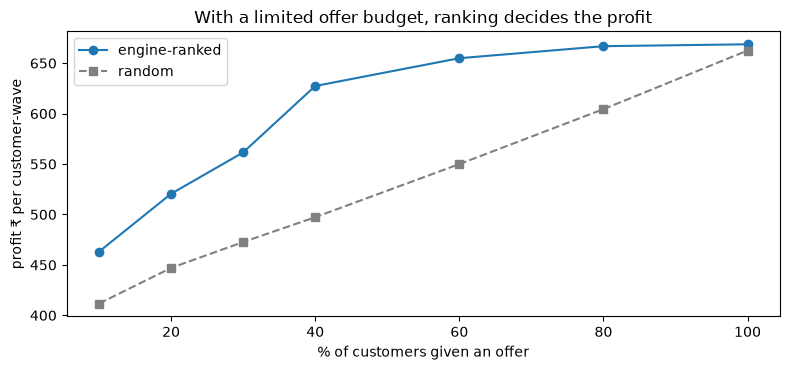

In [7]:
pred = eng.predict(sb_te); pick = pred.idxmax(axis=1).values; gain = pred.max(axis=1).values
r = np.random.default_rng(0).random(len(sb_te)); rows = []
for s in [0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0]:
    k = int(s * len(sb_te)); top = np.argsort(-gain)[:k]; rnd = np.argsort(r)[:k]
    a = np.array(['none'] * len(sb_te), dtype=object); a[top] = pick[top]
    b = np.array(['none'] * len(sb_te), dtype=object); b[rnd] = best
    res = evaluate_policies(sb_te, 'otype', 'val', {'Engine-ranked': a, 'Random': b}, eng.prop, OC, n_boot=200, baseline='Random')
    rows.append({'share offered': s, 'engine ₹': res.loc['Engine-ranked', 'value_per_customer'], 'random ₹': res.loc['Random', 'value_per_customer'],
                 'engine gain ₹': res.loc['Engine-ranked', 'vs_baseline'], 'gain low95': res.loc['Engine-ranked', 'vs_low95'],
                 'gain high95': res.loc['Engine-ranked', 'vs_high95'],
                 'engine reward spend ₹': policy_value(sb_te, 'otype', 'reward_cost', a, eng.prop),
                 'random reward spend ₹': policy_value(sb_te, 'otype', 'reward_cost', b, eng.prop)})
SBB = pd.DataFrame(rows).set_index('share offered'); display(SBB.round(1))
g40 = SBB.loc[0.4]
CHECKS['Offer budget (40% of customers): engine ranking beats random, 95% range above zero'] = g40['gain low95'] > 0
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(SBB.index * 100, SBB['engine ₹'], marker='o', label='engine-ranked'); ax.plot(SBB.index * 100, SBB['random ₹'], marker='s', ls='--', color='grey', label='random')
ax.set_xlabel('% of customers given an offer'); ax.set_ylabel('profit ₹ per customer-wave'); ax.set_title('With a limited offer budget, ranking decides the profit')
ax.legend(); plt.tight_layout(); plt.show()

**B4. Options nobody has tested yet (wallet credit, cashback, bigger discounts).** We cannot measure their uplift without a pilot, but we can say **how much uplift they would need to pay for themselves**. This tells a manager which pilots are worth running.

In [8]:
rows = []
for who, pb in [('Regular (60% buy anyway)', 0.60), ('Occasional (30%)', 0.30), ('Lapsed (10%)', 0.10)]:
    for opt, kw in [('SMS reminder', dict(contact_cost=CHANNELS['SMS'])),
                    ('WhatsApp reminder', dict(contact_cost=CHANNELS['WhatsApp'])),
                    ('₹50 instant discount', dict(contact_cost=CHANNELS['SMS'], reward=50)),
                    ('₹50 cashback, 75% redeemed', dict(contact_cost=CHANNELS['SMS'], reward=50, redeem=REDEEM_CASHBACK)),
                    ('₹30 wallet credit, 75% used', dict(contact_cost=CHANNELS['SMS'], reward=30, redeem=REDEEM_CASHBACK)),
                    ('Free item worth ₹100 (costs ₹85)', dict(contact_cost=CHANNELS['SMS'], reward=100, reward_cost_share=1 - GROSS_MARGIN))]:
        rows.append({'customer': who, 'option': opt, 'needs uplift of (pts)': round(100 * float(breakeven_uplift(pb, MARGIN, **kw)), 1)})
BE = pd.DataFrame(rows).pivot(index='option', columns='customer', values='needs uplift of (pts)')
display(BE[['Regular (60% buy anyway)', 'Occasional (30%)', 'Lapsed (10%)']])
print(f'For reference: the X5 SMS raised buying by {100 * (Y[T == 1].mean() - Y[T == 0].mean()):.1f} pts on average.')

customer,Regular (60% buy anyway),Occasional (30%),Lapsed (10%)
option,,,
Free item worth ₹100 (costs ₹85),78.6,39.4,13.2
SMS reminder,0.1,0.1,0.1
WhatsApp reminder,0.7,0.7,0.7
"₹30 wallet credit, 75% used",10.7,5.4,1.8
"₹50 cashback, 75% redeemed",20.1,10.1,3.4
₹50 instant discount,30.1,15.1,5.1


For reference: the X5 SMS raised buying by 3.3 pts on average.


## Part C · Stress test: what if our assumptions are wrong?
We fix the plan chosen under the base assumptions (X5, WhatsApp, best share) and re-score it when:
- margin is half (₹75), WhatsApp costs double, or the model is 30% too optimistic (real extra buyers 30% lower),
- and all three at once.
The old plan must never lose to contacting everyone, and **re-running the optimiser with the new numbers** must still find a profitable plan (in real life you re-plan when costs or margins change; that is the point of having an optimiser).

,old plan profit ₹,contact-everyone profit ₹,re-optimised share,re-optimised profit ₹,old plan ≥ everyone,re-optimised makes money
scenario,,,,,,
Base,422100.0,396600.0,96%,422100.0,True,True
Margin halved,162100.0,147300.0,72%,165400.0,True,True
WhatsApp cost doubled,324100.0,294600.0,72%,330900.0,True,True
Model 30% too optimistic,266100.0,247000.0,96%,266100.0,True,True
All three at once,-13800.0,-29500.0,16%,55000.0,True,True


plan = contact the top 96% by uplift via WhatsApp


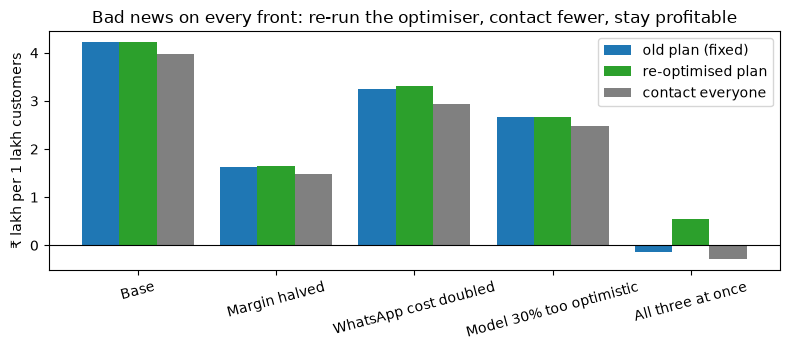

In [9]:
base_share = WC['Uplift champion'].loc[WC['Uplift champion'].profit.idxmax()].share
k = int(round(base_share * len(hold))); o = np.argsort(-SCORES['Uplift champion'], kind='stable')[:k]
lift_sel = Y[o][T[o] == 1].mean() - Y[o][T[o] == 0].mean(); lift_all = Y[T == 1].mean() - Y[T == 0].mean()
rows = []
UC = WC['Uplift champion']
for name, mg, c, f in [('Base', MARGIN, wa, 1.0), ('Margin halved', MARGIN / 2, wa, 1.0), ('WhatsApp cost doubled', MARGIN, 2 * wa, 1.0),
                       ('Model 30% too optimistic', MARGIN, wa, 0.7), ('All three at once', MARGIN / 2, 2 * wa, 0.7)]:
    plan = f * lift_sel * k * SCALE * mg - k * SCALE * c
    everyone = f * lift_all * PER * mg - PER * c
    re_p = f * UC.extra_units * mg - UC.contacts * c; j = re_p.idxmax()       # re-run the optimiser with the new numbers
    rows.append({'scenario': name, 'old plan profit ₹': round(plan, -2), 'contact-everyone profit ₹': round(everyone, -2),
                 're-optimised share': f'{UC.share[j]:.0%}', 're-optimised profit ₹': round(re_p[j], -2),
                 'old plan ≥ everyone': plan >= everyone, 're-optimised makes money': re_p[j] > 0})
ST = pd.DataFrame(rows).set_index('scenario'); display(ST)
print(f'plan = contact the top {base_share:.0%} by uplift via WhatsApp')
CHECKS['Stress test: re-optimised plan stays profitable in every scenario'] = bool(ST['re-optimised makes money'].all())
CHECKS['Stress test: old plan never loses to contacting everyone'] = bool(ST['old plan ≥ everyone'].all())
fig, ax = plt.subplots(figsize=(8, 3.6)); xs = np.arange(len(ST))
ax.bar(xs - 0.27, ST['old plan profit ₹'] / 1e5, 0.27, label='old plan (fixed)'); ax.bar(xs, ST['re-optimised profit ₹'] / 1e5, 0.27, color='tab:green', label='re-optimised plan')
ax.bar(xs + 0.27, ST['contact-everyone profit ₹'] / 1e5, 0.27, color='grey', label='contact everyone')
ax.set_xticks(xs, ST.index, rotation=15); ax.set_ylabel('₹ lakh per 1 lakh customers'); ax.axhline(0, color='black', lw=0.8)
ax.set_title('Bad news on every front: re-run the optimiser, contact fewer, stay profitable'); ax.legend(); plt.tight_layout(); plt.show()

## K5 verdict
- **Budget-limited:** uplift ranking must beat the usual likely-buyer approach, with the 95% range above zero.
- **Offer budget:** engine ranking must beat random at the same size.
- **Stress test:** the old plan never loses to contacting everyone, and the re-optimised plan stays profitable.

In [10]:
pk = CURVES['Uplift champion'].loc[CURVES['Uplift champion'].profit.idxmax()]
CHECKS['Chosen SMS plan profit, 95% range above zero'] = pk.low95 > 0
for k_, v in CHECKS.items(): print(f'{"PASS" if v else "FAIL"}  {k_}')
print('\nK5 VERDICT:', 'PASS' if all(CHECKS.values()) else 'REVIEW')

PASS  Budget-limited: uplift ranking beats likely-buyer, 95% range above zero (₹20k WhatsApp)
PASS  Offer budget (40% of customers): engine ranking beats random, 95% range above zero
PASS  Stress test: re-optimised plan stays profitable in every scenario
PASS  Stress test: old plan never loses to contacting everyone
PASS  Chosen SMS plan profit, 95% range above zero

K5 VERDICT: PASS


## Your notes
- Why is "contact almost everyone" right for SMS, but not with a fixed budget?
- Why can a free item be cheaper than a discount of the same face value?
- Which untested option would you pilot first for lapsed customers, and why?